# Python codes on matrix analysis

Jitkomut Songsiri

These codes are supplementary material for linear algebra application course (2102205). It's intended for students to verify theoretical concepts and practice coding skills.

# Matrix inverse and solving linear equation

For solving $Ax = b$ in square system, consider two cases:
1) Find $A^{-1}$ first and compute $x = A^{-1}b$, using np.linalg.inv
2) Solve the linear equation using np.linalg.solve

find $A^{-1}$ is to solve
$AX = I_n$

In [ ]:
import numpy as np
import time

# Set matrix dimension
n = 4000

# Create a large random matrix A and a vector b
A = np.random.rand(n, n)
b = np.random.rand(n)

print(f"Comparing methods for Matrix Size: {n}x{n}\n")

# --- Method 1: Using np.linalg.inv ---
start_inv = time.time()
A_inv = np.linalg.inv(A)
x_inv = A_inv @ b
end_inv = time.time()
time_inv = end_inv - start_inv
print(f"Time taken using np.linalg.inv: {time_inv:.4f} seconds")

# --- Method 2: Using np.linalg.solve ---
start_solve = time.time()
x_solve = np.linalg.solve(A, b)
end_solve = time.time()
time_solve = end_solve - start_solve
print(f"Time taken using np.linalg.solve: {time_solve:.4f} seconds")

# --- Performance Summary ---
speedup = time_inv / time_solve
print(f"\nSpeedup: np.linalg.solve is {speedup:.2f}x faster than np.linalg.inv")

# Verification: Ensure both results are effectively the same
# (Using allclose due to minor floating point differences)
assert np.allclose(x_inv, x_solve)
print("Results verified: Both methods yielded the same solution.")

Comparing methods for Matrix Size: 4000x4000

Time taken using np.linalg.inv: 7.5493 seconds
Time taken using np.linalg.solve: 1.6601 seconds

Speedup: np.linalg.solve is 4.55x faster than np.linalg.inv
Results verified: Both methods yielded the same solution.


# Matrix pseudo inverse: A is mxn
- Left inverse $A^\dagger = (A^TA)^{-1}A^T$
- Right inverse $A^\dagger = A^T(AA^T)^{-1}$ --> $AA^\dagger = I$

In [ ]:
import numpy as np

# Tall matrix A is m x n
m = 5
n = 3

A = np.random.randint(-5,5,(m,n))
print(f"A is \n {A}")
Ainv = np.linalg.pinv(A)
print(f"Pseudo inverse is \n {Ainv}")
print(f"Check from the expression of pseudo inverse \n {np.linalg.inv(A.T@A)@A.T}")
print(f"Check if it is a left inverse LEFT_INV*A = I {np.allclose(Ainv@A,np.eye(n))}")



A is 
 [[ 4  0 -2]
 [-1  0  2]
 [ 4 -3  0]
 [ 4  2 -3]
 [-4 -3 -2]]
Pseudo inverse is 
 [[ 0.05054566  0.00631821  0.09649627  0.02412407 -0.08041356]
 [-0.01838024 -0.00229753 -0.17145319  0.0821367  -0.10712234]
 [-0.06154099  0.09945023  0.06433084 -0.12677443 -0.14884713]]
Check from the expression of pseudo inverse 
 [[ 0.05054566  0.00631821  0.09649627  0.02412407 -0.08041356]
 [-0.01838024 -0.00229753 -0.17145319  0.0821367  -0.10712234]
 [-0.06154099  0.09945023  0.06433084 -0.12677443 -0.14884713]]
Check if it is a left inverse LEFT_INV*A = I True


In [ ]:
# Fal matrix m x n

m = 5
n = 7

A = XXXX

Ainv = XXXX


Tall matrix case:

Given $A, b$ (randomization)
find $A^\dagger$

if we construct $x = A^\dagger b$, is $Ax = b$?

In [ ]:
import numpy as np
m = 10
n = 5

A = np.random.randint(-5,5,(m,n))
b = np.random.randint(-5,5,m)

x = np.linalg.pinv(A)@b
print(x)

# check if Ax = b ?


[-0.13871956  0.31661392  0.03766009  0.10023585 -0.26516753]


# Direction of eigenvectors

Key messages
- When $A$ has real eigenvalues, $Ax = \lambda x$: an eigenvector is mapped under $A$ to a new vector in the same direction, $\lambda x$.
- For other vectors $z$, $Az$ may have different direction from $z$.

Symmetric Matrix A:
 [[-1.  -1.5]
 [-1.5  0. ]]

Real Eigenvalues (a): [-2.08113883  1.08113883]
Eigenvectors (x):
 [[-0.81124219  0.58471028]
 [-0.58471028 -0.81124219]]


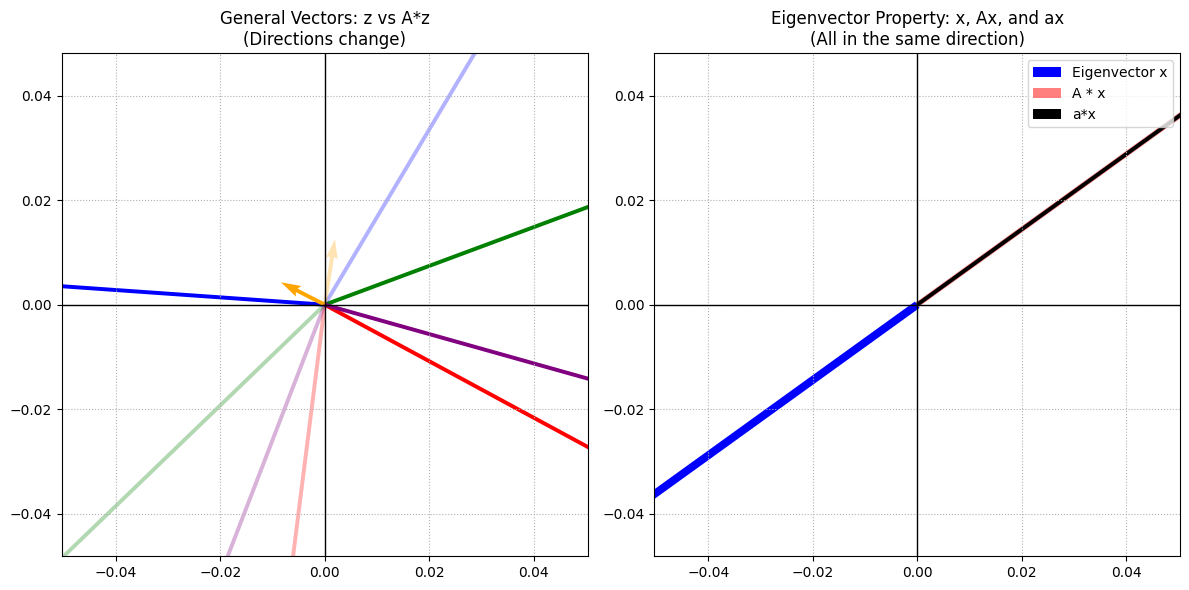

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# 1) Generate a symmetric matrix A to ensure real eigenvalues
n = 2
# We generate a random integer matrix, then symmetrize it
A_raw = np.random.randint(-2, 3, size=(n, n)).astype(float)
A = (A_raw + A_raw.T) / 2

# Find eigenvalues (a) and eigenvectors (x)
a, x = np.linalg.eig(A)

print("Symmetric Matrix A:\n", A)
print("\nReal Eigenvalues (a):", a)
print("Eigenvectors (x):\n", x)

# 2) Generate 5 random vectors z stored in Z
Num = 5
np.random.seed(10)
Z = np.random.randn(2, Num)

# Setup Visualization
plt.figure(figsize=(12, 6))

# --- 3) Plot Random Vectors z and A*z ---
plt.subplot(1, 2, 1)
colors = ['red', 'green', 'blue', 'orange', 'purple']

for i in range(Num):
    z = Z[:, i]
    Az = A @ z
    # Plot z
    plt.quiver(0, 0, z[0], z[1], angles='xy', scale_units='xy', scale=1,
               color=colors[i], label=f'z{i+1}' if i==0 else "")
    # Plot Az (dashed and faded)
    plt.quiver(0, 0, Az[0], Az[1], angles='xy', scale_units='xy', scale=1,
               color=colors[i], alpha=0.3, linestyle='--')

plt.title("General Vectors: z vs A*z\n(Directions change)")
plt.axhline(0, color='black', lw=1); plt.axvline(0, color='black', lw=1)
plt.grid(True, linestyle=':')
plt.axis('equal')

# --- 4) Plot Eigenvector x, A*x, and a*x ---
plt.subplot(1, 2, 2)

# We'll use the first eigenvector for the demonstration
v = x[:, 0]
eig_val = a[0]
Av = A @ v
av = eig_val * v

# Plotting with different widths so they are visible even when overlapping
plt.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=1,
           color='blue', width=0.015, label='Eigenvector x')
plt.quiver(0, 0, Av[0], Av[1], angles='xy', scale_units='xy', scale=1,
           color='red', width=0.01, alpha=0.5, label='A * x')
plt.quiver(0, 0, av[0], av[1], angles='xy', scale_units='xy', scale=1, color = 'black', label = 'a*x')

plt.title("Eigenvector Property: x, Ax, and ax\n(All in the same direction)")
plt.axhline(0, color='black', lw=1); plt.axvline(0, color='black', lw=1)
plt.grid(True, linestyle=':')
plt.axis('equal')
plt.legend()

plt.tight_layout()
plt.show()


# Eigenvalues of some special matrices.

Any analytical results of eigenvalues for these structured matrices?
- $A$ is diagonal
- $A$ is triangular
- $A$ is an elementary matrix obtained from swapping rows.

In [ ]:
import numpy as np

n = 10

# Diagonal case
A1 = np.diag( np.random.randint(-10,10,n) )
print(f"A1 is diagonal \n {A1}")

a1, X1 = np.linalg.eig(A1)
print(f"eigenvalues of A1 are {a1}")
print(f"eigenvectors of A1 are\n {X1}")

# Triangular case
A2 =np.random.randint(-5,5,(n,n))
A2 = np.tril(A2)
print(f"A2 is lower triangular \n {A2}")
# ---- FILL YOUR CODE ----
a2, X2 = np.linalg.eig(A2)


# Elementary matrix obtained by swapping rows
I = np.eye(n)
idx = np.random.permutation(n)
print(idx)
# idx = [3,1,2,0,4]
A3 = I[idx,:]
print(f"A3 is obtained by swapping rows of I \n {A3}")
# ---- FILL YOUR CODE ----
a3, X3 = np.linalg.eig(A3)

# modulus_a3 = XXXXX
print(f"eigenvalues of A3 are {a3}")
print(f"eigenvectors of A3 are\n {X3}")

A1 is diagonal 
 [[-4  0  0  0  0  0  0  0  0  0]
 [ 0  5  0  0  0  0  0  0  0  0]
 [ 0  0  5  0  0  0  0  0  0  0]
 [ 0  0  0  9  0  0  0  0  0  0]
 [ 0  0  0  0 -8  0  0  0  0  0]
 [ 0  0  0  0  0 -9  0  0  0  0]
 [ 0  0  0  0  0  0 -5  0  0  0]
 [ 0  0  0  0  0  0  0  1  0  0]
 [ 0  0  0  0  0  0  0  0  4  0]
 [ 0  0  0  0  0  0  0  0  0 -9]]
eigenvalues of A1 are [-4.  5.  5.  9. -8. -9. -5.  1.  4. -9.]
eigenvectors of A1 are
 [[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]
A2 is lower triangular 
 [[-5  0  0  0  0  0  0  0  0  0]
 [ 3 -3  0  0  0  0  0  0  0  0]
 [-1  1  0  0  0  0  0  0  0  0]
 [ 3  2 -4 -5  0  0  0  0  0  0]
 [-1 -5 -1  2  4  0  0  0  0  0]
 [ 2  3 -2 -1  3  3  0  0  0  0]
 [ 0  4 -3

In [ ]:
print(idx)


[1 0 7 5 2 4 3 8 9 6]


# Properties of eigenvalues

1. $\lambda(A) = \lambda(A^T)$ (the set of eigenvalues are the same)
2. $\lambda(A^n) = (\lambda(A))^n$
3. $\lambda(\alpha A) = \alpha \lambda(A)$
4. $\lambda(p(A)) = p(\lambda(A))$
5. If $A$ is invertible, then $\lambda(A) \neq 0$ and that  $\lambda(A^{-1}) = 1/\lambda(A)$
6. $\mathbf{Tr}(A) = \sum_{i=1}^n \lambda_i(A)$
7. $\mathbf{det}(A) = \prod_{i=1}^n \lambda_i(A)$

In [ ]:
import numpy as np

n = 5

A = np.random.randint(-3,3,(n,n))
A = (A+A.T)/2 # make it symmetric so eigenvalues are real
# p(A) = A^2 - 3A + 5I
pA = np.linalg.matrix_power(A,2)-3*A+5*np.eye(n)  # be aware that A^2 is not A**2 !

a, X = np.linalg.eig(A)
print(f" eigenvalues of A are {np.round(a,2)}")

eigenAt = np.linalg.eig(A.T)[0] # return only eigenvalues
print(f" eigenvalues of A-transpose are {np.round(eigenAt,2)}")

eigenpA,_ = np.linalg.eig(pA) # same as throw away the eigenvectors

print(f"p(A) = A^2 - 3A + 5I")
print(f" eigenvalues of p(A) are {np.round(eigenpA,2)}")
print(f" p(lambda) are {np.round( a**2-3*a+5,2)} ")

# ---- Code the trace and det properties



 eigenvalues of A are [-4.38 -2.42  1.08  5.15  3.57]
 eigenvalues of A-transpose are [-4.38 -2.42  1.08  5.15  3.57]
p(A) = A^2 - 3A + 5I
 eigenvalues of p(A) are [37.29  2.93  7.04 18.15 16.09]
 p(lambda) are [37.29 18.15  2.93 16.09  7.04] 


np.float64(2.999999999999998)

# Cosine similarity of $Ax$ and $x$.
Define cosine similarity between two vectors, $x$ and $y$ as
$$
\cos(\theta) = \frac{x^Ty}{\Vert x \Vert \Vert y \Vert}
$$
Let $A$ be a symmetric of size $n$. Find $x \neq 0 $ that maximizes the cosine similarity between $x$ and $Ax$. Does such a solution always exist? Is the choice of $x$ unique?



In [ ]:
import numpy as np

n = 10
A = np.random.randint(-5,5,(n,n))
A = (A+A.T)/2
print(f"A is \n {A}")

#===== your code =====
# x = XXX

A is 
 [[ 0.   1.5 -4.  -3.   1.5 -2.  -4.5 -4.  -1.  -3.5]
 [ 1.5 -3.  -1.5 -1.   0.  -3.  -3.5 -3.5 -1.  -1. ]
 [-4.  -1.5  0.  -3.5  0.  -3.5 -0.5  0.5  0.5  1. ]
 [-3.  -1.  -3.5  2.  -0.5 -1.5 -0.5 -4.   2.  -3. ]
 [ 1.5  0.   0.  -0.5 -1.  -3.  -2.5 -2.5  1.   1. ]
 [-2.  -3.  -3.5 -1.5 -3.   3.   3.5 -1.  -2.5  0. ]
 [-4.5 -3.5 -0.5 -0.5 -2.5  3.5 -3.   1.  -3.5  0. ]
 [-4.  -3.5  0.5 -4.  -2.5 -1.   1.  -2.  -1.   4. ]
 [-1.  -1.   0.5  2.   1.  -2.5 -3.5 -1.  -3.   1. ]
 [-3.5 -1.   1.  -3.   1.   0.   0.   4.   1.   4. ]]


# Check the locations of eigenvalues

When studying about dynamical systems, we will see that the location of eigenvalues determine the decay rate of the system response. For this reason, it's a good practice to be able to check if

1. Case 1: the real part of eigenvalues are negative or not,
2. Case 2: The modulus of eigenvalues are less than one or not.
3. Plot the locations of eigenvalues on the complex plane (actually $R^2$ plane: real part and imaginary part).

In [ ]:
import numpy as np

n = 10

A = np.random.randn(n,n)

a,_ = np.linalg.eig(A)

# check if real part of a <= 0

# check if |a| < 1

# plot real part of a versus imaginary part of a.


# Orthogonal matrix

$A$ is orthogonal if $A^TA = AA^T =I$. Its properties are

1. eigenvalues have a unit modulus, $|\lambda(A)| = 1$.
2. $\det(A) = 1$.
3. All columns are mutually orthogonal.

To generate an orthogonal matrix *randomly*, we rely on the concept of *QR decomposition* that says any $B \in \mathbf{R}^{m \times n}$ can be decomposed as $B = QR$ where $Q \in \mathbf{R}^{m \times m}$ is orthogonal and $R \in \mathbf{R}^{n \times n}$ is upper triangular.
This can be obtained using `np.linalg.qr`

A is 
 [[-0.33180076  0.11265585  0.33878546  0.01234317  0.12058156 -0.0252726
   0.48598883 -0.71479033]
 [-0.33180076 -0.12348814  0.03085894 -0.40279923  0.01152869  0.57349365
   0.44672816  0.42762777]
 [-0.33180076 -0.12348814 -0.40716066 -0.67637761 -0.06409694 -0.16477856
  -0.34966949 -0.31283113]
 [ 0.16590038  0.29788806  0.34724949 -0.29589042  0.7384473   0.15263367
  -0.32600511  0.02693748]
 [ 0.38710088  0.41957082 -0.24252983 -0.35462511  0.03292054 -0.43835485
   0.52509335  0.14342869]
 [-0.44240101  0.11085047  0.54639939 -0.10375673 -0.1993749  -0.529178
  -0.11506978  0.38685269]
 [ 0.49770114 -0.05091178  0.46707183 -0.37794195 -0.54376058  0.21652445
  -0.09878814 -0.190756  ]
 [-0.22120051  0.8228932  -0.14960286  0.11488281 -0.31528505  0.31772653
  -0.19229549 -0.03171255]]
Make sure that A^TA = I 
 [[ 1. -0.  0. -0. -0.  0. -0.  0.]
 [-0.  1. -0.  0. -0. -0. -0. -0.]
 [ 0. -0.  1.  0.  0.  0.  0.  0.]
 [-0.  0.  0.  1.  0. -0.  0. -0.]
 [-0. -0.  0.  0.  1.

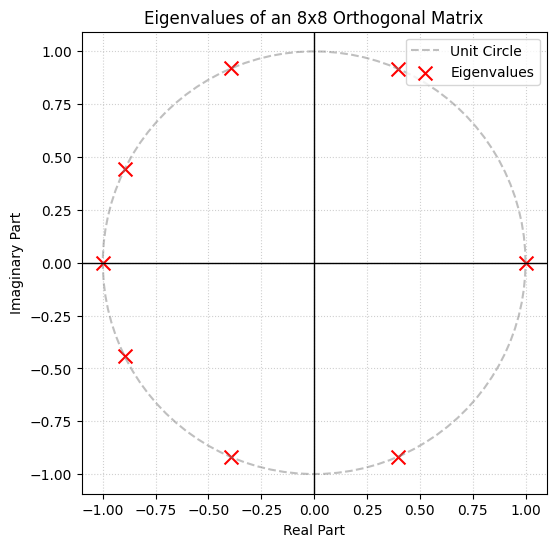

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n = 8

# Generate an orthogonal A randomly using QR of another matrix.

B = np.random.randint(-10,10,(n,n))
A,_ = np.linalg.qr(B)
d,V = np.linalg.eig(A)
real_eigen = d.real
imag_eigen = d.imag

print(f"A is \n {A}")
print(f"Make sure that A^TA = I \n {np.round(A.T@A,2)}")
print(f"Check modulus of eigenvalues {np.abs(d)}")

# plot eigenvalues on the complex plane.

plt.figure(figsize=(6, 6))

# 1. Plot the Unit Circle for reference
theta = np.linspace(0, 2*np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--', alpha=0.5, label='Unit Circle')

# 2. Plot the Eigenvalues
plt.scatter(real_eigen, imag_eigen, marker='x', color='red', s=100, label='Eigenvalues')

# 3. Formatting the plot
plt.axhline(0, color='black', lw=1) # Real axis
plt.axvline(0, color='black', lw=1) # Imaginary axis
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlabel("Real Part")
plt.ylabel("Imaginary Part")
plt.title(f"Eigenvalues of an {n}x{n} Orthogonal Matrix")
plt.legend(loc='upper right')

# Ensure the plot is square so the circle doesn't look like an ellipse
plt.axis('equal')

plt.show()

# Projection and Orthogonal projection matrices

Recall the definitions:
1. Projection: $P^2 = P$.
2. Orthogonal projection: $P^2 = P$ and $P=P^T$.

Properties:
1. Eigenvalues of projection matrix are either 0 or 1 (in fact, this is equivalent to the definition.), i.e., If eigenvalues are 0 or 1, then $P$ is idempotent.
2. Orthogonal projection matrix has bounded property:
$\Vert Px \Vert \leq \Vert x \Vert$.
3. Residual after orthogonal projection is orthogonal to the projected vector, \ie,
$$
(x-Px)^T(Px) = 0.
$$

## Random generation of projection matrices.

As eigenvalues of $P$ are either 0, or 1, we can use similarity transform.

- Generate $D$ that contains either 0 or 1 in the diagonal.
- Generate an invertible $T$ randomly.
- $P = TDT^{-1}$.

(note that $P$ is not necessarily symmetric).

In [ ]:
import numpy as np

n = 4

d = np.ones(n)
idx = np.random.permutation(n)
num_eigenzero = int(np.floor(0.3*n)) # says, 30% of all eigenvalue are zeros.
d[idx[:num_eigenzero]] = 0
print(f"Eigenvalues of P are {d}")
T = np.random.randint(-5,5,(n,n))
Tinv = np.linalg.inv(T)
print(f"T is \n {T}")
print(f"Inverse of T is \n {Tinv}")
Tinv = np.linalg.inv(T)
P = T@np.diag(d)@Tinv
print(f"A random example of P \n {np.round(P,2)}")
print(f"Check if P^2 = P {np.allclose(P,P@P)}")

Eigenvalues of P are [1. 1. 1. 0.]
T is 
 [[-1  0 -4 -2]
 [-4 -3  2  1]
 [-5 -5  0  3]
 [ 1  4  3  3]]
Inverse of T is 
 [[-0.26190476 -0.30952381  0.07142857 -0.14285714]
 [ 0.22619048  0.13095238 -0.10714286  0.21428571]
 [-0.1547619   0.22619048 -0.1547619  -0.02380952]
 [-0.05952381 -0.29761905  0.27380952  0.11904762]]
A random example of P 
 [[ 0.88 -0.6   0.55  0.24]
 [ 0.06  1.3  -0.27 -0.12]
 [ 0.18  0.89  0.18 -0.36]
 [ 0.18  0.89 -0.82  0.64]]
Check if P^2 = P True


## Random generation of orthogonal projection matrices.

We can use $P = UDU^T$ (called congruence transform) where $U$ is orthogonal.

- Generate $D$ that contains either 0 or 1 in the diagonal.
- Generate an orthogonal $U$ randomly.
- $P = UDU^T$.

(verify it yourself that $P$ generated this way is orthogonal projection.)

To do so, we can just borrow the decomposition of a symmetric matrix, $B = UDU^T$, and replace eigenvalues in $D$ to be either 0 or 1. (To understand this, you must read the properties of symmetric matrices first).

In [ ]:
import numpy as np

n = 4

d = np.ones(n)
idx = np.random.permutation(n)
num_eigenzero = int(np.floor(0.3*n)) # says, 30% of all eigenvalue are zeros.
d[idx[:num_eigenzero]] = 0
print(f"Eigenvalues of P are {d}")

B = np.random.randint(-5,5,(n,n))
B = (B+B.T)/2  # make B symmetric
_,U = np.linalg.eigh(B)  # since B is symmetric, U (eigenvectors) are orthogonal

P = U@np.diag(d)@U.T

print(f"U is \n {T}")
print(f"A random example of P \n {np.round(P,2)}")
print(f"Check if P^2 = P: {np.allclose(P,P@P)}")
print(f"Check if P is symmetric: {np.allclose(P,P.T)}")

Eigenvalues of P are [1. 1. 0. 1.]


NameError: name 'T' is not defined

## Example of orthogonal projection matrix.

Example 1: $P = uu^T$ where $u$ is a unit-norm vector.

Result: $Px$ is a projection of $x$ on the line along vector $u$ direction.
$$
Px = uu^Tx = (u^Tx)u = \Vert x \Vert \cos\theta \cdot u
$$
(familiar result in high school ?)

The following is my AI prompt to Gemini to generate python codes. These are step-by-step command that has clear set of instructions.
-------------------------------------------
I wanna illustrate an orthogonal projection matrix given by

P = u*u^T where u is a unit norm vector.

This example is in R^2.
1) Generate a unit-norm vector u randomly.
2) Calculate P = u@u^T
3) Let $x$ be a random vector in R^2, calculate vector Px = P@x.
4) Calculate residual after projection, r = x-Px.
5) Plot a line along direction u (line is extended). Plot x, Px, r. This is to show that Px is along the line, r is perpendicular to Px.

Give me python codes to do the above.
--------------------------------------------

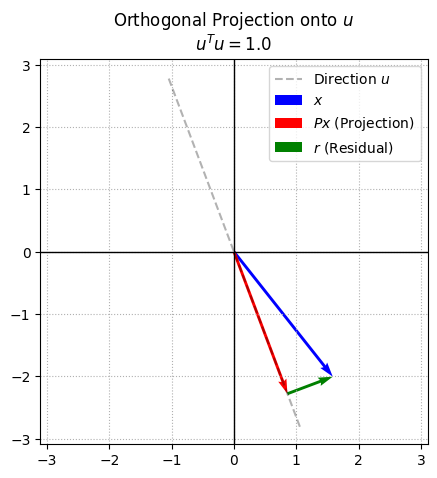

Dot product of Px and r: -8.88e-16


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a unit-norm vector u randomly
alpha = np.random.uniform(0, 2 * np.pi)
u = np.array([np.cos(alpha), np.sin(alpha)]).reshape(-1, 1)

# 2. Calculate P = u * u^T
P = u @ u.T

# 3. Let x be a random vector, calculate Px
x = np.random.randn(2, 1)
Px = P @ x

# 4. Calculate residual r = x - Px
r = x - Px

# 5. Plotting
plt.figure(figsize=(5,5))

# Plot the line along direction u (extended for visualization)
line_scale = 3
plt.plot([-line_scale*u[0,0], line_scale*u[0,0]],
         [-line_scale*u[1,0], line_scale*u[1,0]],
         'k--', alpha=0.3, label='Direction $u$')

# Plot the vectors
# We use quiver to plot them as arrows starting from the origin (except r)
origin = [0], [0]

# Vector x
plt.quiver(*origin, x[0], x[1], color='blue', angles='xy', scale_units='xy', scale=1, label='$x$')
# Vector Px
plt.quiver(*origin, Px[0], Px[1], color='red', angles='xy', scale_units='xy', scale=1, label='$Px$ (Projection)')
# Vector r (plotted starting from Px to show it reaches x)
plt.quiver(Px[0], Px[1], r[0], r[1], color='green', angles='xy', scale_units='xy', scale=1, label='$r$ (Residual)')

# Formatting
plt.axhline(0, color='black', lw=1)
plt.axvline(0, color='black', lw=1)
plt.axis('equal') # CRITICAL for seeing the 90-degree angle
plt.grid(True, linestyle=':')
plt.legend()
plt.title(f'Orthogonal Projection onto $u$\n$u^T u = {np.linalg.norm(u)**2:.1f}$')

plt.show()

# Verification print
print(f"Dot product of Px and r: {np.dot(Px.flatten(), r.flatten()):.2e}")

# Symmetric matrices

$A$ is symmetric. Recall its properties:

- eigenvalues are real
- eigenvectors are orthogonal
- $A = UDU^T$
- $\lambda_{\min}(A)\Vert x \Vert^2 \leq x^T Ax \leq \lambda_{\max}(A) \Vert x \Vert^2$, for all $x$.

Using `np.linalg.eigh` specifically for symmetric matrices is more efficient than `np.linalg.eig`.

In [ ]:
import numpy as np

n = 5

A = np.random.randint(-10,10,(n,n))
A = (A+A.T)/2

print(f"A is \n {A}")

d,V = np.linalg.eigh(A)
print(f"eigenvalues are real? {np.round(d,2)}")
print(f"Eigenvectors are orthogonal? ")
print(f"Eigenvectors are \n {np.round(V,2)}")
print(f"Check if V^TV = I \n {np.round(V.T@V,2)}")

# Positive semidefinite (psdf) matrix

Equivalent condition of positive semidefinite matrix $A$.

- All eigenvalues are non-negative.
- All principal minors are non-negative.

An important example of psdf matrix is a *Gram matrix*. Let $B$ be any regtangular matrix, $A = B^TB$ is always psdf.

To generate a psdf $A$, we can generate a Gram matrix.

## Check properties

In [ ]:
import numpy as np

n = 6
B = np.random.randint(-2,2,(n,n))
# A = B.T@B # make sure that A >= 0
A = B.T+B  # only symmetric and eigenvalues are real
d, V = np.linalg.eigh(A)

print(f"A is \n {A}")
print(f"Are all eigenvalues non-negative? \n {np.round(d,2)}")

# check all principal minors
print(f"Check by principal minor")
for k in range(n):
  Ak = A[:k,:k]
  print(f"{k} principal minor = det(Ak) = {np.linalg.det(Ak)}")


A is 
 [[-2 -1 -1  2 -2 -2]
 [-1 -4 -2 -1  0  0]
 [-1 -2 -4  0  1 -2]
 [ 2 -1  0 -2 -2 -1]
 [-2  0  1 -2 -2  1]
 [-2  0 -2 -1  1  0]]
Are all eigenvalues non-negative? 
 [-7.07 -4.47 -3.9  -2.26  0.02  3.69]
Check by principal minor
0 principal minor = det(Ak) = 1.0
1 principal minor = det(Ak) = -2.0
2 principal minor = det(Ak) = 7.000000000000001
3 principal minor = det(Ak) = -20.000000000000007
4 principal minor = det(Ak) = -23.00000000000001
5 principal minor = det(Ak) = 406.00000000000034


In [ ]:
import numpy as np

n = 7

A = np.random.randint(-2,2,(n,n))
A = A.T@A
d,_ = np.linalg.eigh(A)

print(f"eigenvalues of A {d}")
# size of leading block
r = 3
print(f"A is \n {A}")
Ablk = A[:r,:r]
print(f"Ablk is \n {Ablk}")
d1,_ = np.linalg.eigh(Ablk)
print(f"eigenvalues of Ablk is {d1}")

eigenvalues of A [ 0.71163001  1.14593566  1.69471984  4.36001064 10.97834267 16.15633408
 23.95302711]
A is 
 [[ 4 -2  1 -4  0  1 -3]
 [-2  8  6  0 -2  0 -2]
 [ 1  6 12 -4 -2  4 -2]
 [-4  0 -4 12  2  0  6]
 [ 0 -2 -2  2  2  1  3]
 [ 1  0  4  0  1  7  4]
 [-3 -2 -2  6  3  4 14]]
Ablk is 
 [[ 4 -2  1]
 [-2  8  6]
 [ 1  6 12]]
eigenvalues of Ablk is [ 1.62052335  6.04418604 16.33529061]


## How to make a perturbed matrix pdf.

Given $A$ that is indefinite (eigenvalues of $A$ have mixed signs). Consider a perturbation on $A$ given by
$$
B = A + cI, \quad c \in \mathbf{R}.
$$
Under which condition does $B$ become positive definite? Derive the condition and implement the code. If the condition is a range on $c$, pick one suitable value.

In [ ]:
import numpy as np

n = 5

A = np.random.randint(-2,2,(n,n))
A = (A+A.T)/2
d, V = np.linalg.eigh(A)

print(f"eigenvalues of A are {np.round(d,2)}")

# ------ Code your answer here ------- #

eigenvalues of A are [-4.24 -1.44 -0.2   0.74  1.15]


# Permutation matrix

Recall the definition: $P$ is obtained by interchanging rows in $I$.

Equivalent condition: $P$ has 1 as the only non-zero entry in each column. The positions of 1's occur at different positions.

Properties:
- $P^TP = I$ --> automatically makes $P$ orthogonal.
- $PA$ permutes rows in $A$; $AP$ permutes columns in $A$.
- If $P$ is obtained by a single swap of rows in $I$, $P^2= I$ (because $P$ is an elementatry matrix).

Random generation: super easy. Just permute rows in $I$ !

In [ ]:
import numpy as np

n = 5
I = np.eye(n)

A = np.random.randint(-3,3,(n,n))
# generate a permuted index from 0:n-1
idx = np.random.permutation(n)
P = I[idx,:]

print(f"permuted index is {idx}")
print(f"P is \n {P}")
print(f"A is \n {A}")

# Permute rows in A
print(f"PA is \n {P@A}")
print(f"which is the same as indexing in A \n {A[idx,:]}")

# Permute columns in A
# --------Fill your code ---------#

permuted index is [4 2 1 3 0]
P is 
 [[0. 0. 0. 0. 1.]
 [0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]]
A is 
 [[-2 -1  0  1 -3]
 [-3 -1 -1 -1 -1]
 [ 2 -2 -1 -1 -1]
 [-2 -2 -1 -2 -2]
 [ 1  2 -1 -1  0]]
PA is 
 [[ 1.  2. -1. -1.  0.]
 [ 2. -2. -1. -1. -1.]
 [-3. -1. -1. -1. -1.]
 [-2. -2. -1. -2. -2.]
 [-2. -1.  0.  1. -3.]]
which is the same as indexing in A 
 [[ 1  2 -1 -1  0]
 [ 2 -2 -1 -1 -1]
 [-3 -1 -1 -1 -1]
 [-2 -2 -1 -2 -2]
 [-2 -1  0  1 -3]]


# Nullspace of a matrix.
Let $A \in \mathbf{R}^{m \times n}$.

- Sympy: `A.nullspace()` : The answers follows the hand calculation when solving $Ax =0$ by Gaussian elimination.
- Scipy: `scipy.linalg.null_space`: Use singular value decomposition (SVD) where $A = U\Sigma V^T$ and the nullspace vectors are the rows of $V$ (requires further reading).

For these reasons, the two commands do not return the same results.

Let $V \in \mathbf{R}^{n \times r}$ be the result returned by these commands. Each column of $V$ is a vector lying in the nullspace of $A$. You can check the dimension of nullspace of $A$ is $r$.

In [6]:
import numpy as np
import sympy as sp
from scipy.linalg import null_space

A = np.array([[1,-1,5,-2,2],[2,-2,-2,5,1],[0,0,1,2,3],[-1,1,7,-7,1]])
ns = null_space(A)

A1 = sp.Matrix(A)
ns1 = A1.nullspace()

print("A is \n")
sp.pprint(A1)
print(f"Nullspace of A using Scipy is \n {ns}")
print(f"Nullspace of A using Sympy is \n {ns1}")

A is 

⎡1   -1  5   -2  2⎤
⎢                 ⎥
⎢2   -2  -2  5   1⎥
⎢                 ⎥
⎢0   0   1   2   3⎥
⎢                 ⎥
⎣-1  1   7   -7  1⎦
Nullspace of A using Scipy is 
 [[-0.52182422  0.546926  ]
 [-0.02961062  0.75534878]
 [ 0.4922136   0.20842278]
 [ 0.4922136   0.20842278]
 [-0.4922136  -0.20842278]]
Nullspace of A using Sympy is 
 [Matrix([
[1],
[1],
[0],
[0],
[0]]), Matrix([
[ 1],
[ 0],
[-1],
[-1],
[ 1]])]
